# 05 — 적합도 예측 신뢰도 보정 (`results/calib_logistic`)

회귀 모델이 내는 예측 평균 $\mu$ (`fitness_z`) · 가지 간 표준편차 $\sigma$ (`fitness_sd`) 로부터 예측마다 신뢰도 2종을 확률로 계산하는 함수를 만든다. 보정 자료는 서비스 회귀 모델과 같은 입력 조합(`noseq`)의 **교차검증 예측** 이다. 각 예측은 그 유전자의 genus 를 학습에 쓰지 않은 모델이 낸 값이라, 새 균주를 예측할 때의 오차 양상을 담는다.

| 신뢰도 | 정의 | 범위 | 보정 함수 |
|---|---|---|---|
| `conf_sign` | 실제 적합도가 예측 쪽(균주 평균보다 높음 / 낮음)에 있을 확률 — 방향 신뢰도 | 0.5 ~ 1 | 라벨 잡음을 반영한 로지스틱 |
| `conf_fit` | 실측 적합도(`fit_mean`, 균주 내 z)가 예측 구간 $\mu \pm \sigma$ 안에 있을 확률 — 구간 적중 확률 | 0 ~ 1 | 기울기 부스팅 확률표 |

| 파일 (`results/calib_logistic/`) | 내용 |
|---|---|
| `calibration.json` | `conf_sign` 로지스틱 계수 · `conf_fit` 확률표 (서비스 `assets/` 에 그대로 복사해 쓴다) |
| `check_conf_sign.csv` · `check_conf_fit.csv` | genus 단위 검증 — 예측 확률 구간별 실제 비율 |
| `calibration.png` | 같은 검증의 보정 그림 |

진행: 1 데이터 → 2 방향 신뢰도 → 3 구간 적중 확률 → 4 genus 단위 검증 → 5 최종 보정 함수

In [1]:
import os, json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm
from scipy.interpolate import RegularGridInterpolator
from sklearn.ensemble import HistGradientBoostingClassifier
from proteomefit import data
from proteomefit.config import Config

cfg      = Config()                                   # base data 경로
CV_DIR   = '../results/fitpred_ablation/noseq'         # 서비스 회귀 모델과 같은 입력 조합의 교차검증 결과
OUT_DIR  = '../results/calib_logistic'
GRID_MU  = np.round(np.arange(-8, 2.01, 0.1), 2)      # conf_fit 확률표의 mu 격자 [101]
GRID_LSD = np.round(np.arange(-1.6, 1.21, 0.1), 2)    # conf_fit 확률표의 log(sd) 격자 [29]
SE_MAX   = 0.25                                        # conf_sign 검증에 쓰는 라벨 측정 오차 상한 (z 단위)
BINS     = [0, .2, .3, .4, .5, .6, .7, .8, .9, 1.01]   # 검증 표의 확률 구간
os.makedirs(OUT_DIR, exist_ok=True)

## 1. 데이터 — 교차검증 예측과 라벨

| 기호 | 형태 | 내용 |
|---|---|---|
| $\mu$ · $\sigma$ | `[n_pred]` | `CV_DIR/fold##_<genus>/inner##/pred.npz` 의 `mu` · `sd` (28 외부 폴드 x 내부 폴드 3개, 시험 genus 샘플 순서) |
| $y$ | `[n_pred]` | 균주 내 z-정규화 `fit_mean` (회귀 라벨과 같다) |
| $se$ | `[n_pred]` | 라벨 측정 오차 = `comb_se` / 균주별 `fit_mean` 표준편차 (z 단위) |

$$y_i = \frac{f_i - \bar{f}_{o(i)}}{s_{o(i)}}, \qquad se_i = \frac{\mathrm{comb\_se}_i}{s_{o(i)}}$$

- $f_i$ — 원본 `fit_mean`, $\bar{f}_o$ · $s_o$ — 균주 $o$ 의 `fit_mean` 평균 · 표준편차
- 예: $s_o = 0.8$, `comb_se` = 0.2 → $se = 0.25$. 측정 오차가 라벨 단위로 0.25 라는 뜻이다
- 같은 유전자가 내부 폴드 3개에서 한 번씩 예측되므로 예측 수는 유전자 수의 3배다

In [2]:
# 라벨 - 적합도 수치가 있는 샘플 (회귀 학습 샘플과 같은 순서) [n]
D      = data.load_samples(cfg.base_dir, cfg.label_col, finite_only=True)
se_all = data.load_basedata(cfg.base_dir, usecols=['comb_se']).comb_se.to_numpy(float)   # [n_all]
fit    = D.yb[D.keep]                                          # 원본 적합도 [n]
g      = pd.Series(fit).groupby(D.org)
sd_org = g.transform('std').to_numpy()                         # 균주별 fit_mean 표준편차 [n]
y      = ((fit - g.transform('mean')) / sd_org).to_numpy()     # 라벨 (균주 내 z) [n]
se     = se_all[D.keep] / sd_org                               # 라벨 측정 오차 (z 단위) [n]

# 교차검증 예측 [n_pred, 5]
rows = []
for d in sorted(glob.glob(f'{CV_DIR}/fold*')):
    genus = os.path.basename(d).split('_', 1)[1]
    te    = np.flatnonzero(D.gen == genus)                     # 시험 샘플 (pred.npz 와 같은 순서)
    for f in sorted(glob.glob(f'{d}/inner*/pred.npz')):
        z = np.load(f)
        rows.append(pd.DataFrame({'mu': z['mu'], 'sd': z['sd'], 'y': y[te], 'se': se[te], 'genus': genus}))
R = pd.concat(rows, ignore_index=True)
print(f'cross-validation predictions: {len(R):,} | genera {R.genus.nunique()} | genes {len(y):,}')
print(f'label se (z): median {R.se.median():.3f} | share se <= {SE_MAX}: {(R.se <= SE_MAX).mean():.1%}')
print(f'mu: median |mu| {R.mu.abs().median():.3f} | sd: median {R.sd.median():.3f}')

cross-validation predictions: 531,951 | genera 28 | genes 177,317
label se (z): median 0.472 | share se <= 0.25: 11.0%
mu: median |mu| 0.456 | sd: median 0.530


## 2. 방향 신뢰도 `conf_sign` — 라벨 잡음을 반영한 로지스틱

$$p = \mathrm{logistic}(\mathbf{w} \cdot \mathbf{x}), \qquad \mathbf{x} = \big(1,\ L,\ S,\ L S\big), \qquad L = \log(\lvert\mu\rvert + 0.05), \qquad S = \log\sigma$$

- $L$ — 예측 효과 크기. 0.05 를 더해 $\mu = 0$ 에서도 유한하다
- $S$ — 예측 불확실도. 미니 MLP 가지들이 서로 얼마나 다르게 예측했는가
- $L S$ — 두 항의 곱. 같은 $\sigma$ 라도 $\lvert\mu\rvert$ 에 따라 효과가 달라지는 것을 담는다
- 예: $\mu = -1.0,\ \sigma = 0.5$ → $L = \log 1.05 = 0.049$, $S = \log 0.5 = -0.693$

$p$ 는 **실제** 적합도 $y^*$ 가 예측과 같은 부호일 확률이다. 관측 라벨은 측정 오차로 부호가 뒤집힐 수 있으므로, 관측 부호가 예측과 같을 확률을 다음처럼 두고 전체 유전자에서 우도를 최대화해 $\mathbf{w}$ 를 구한다.

$$P(\text{관측 부호 일치}) = r\,p + (1 - r)(1 - p), \qquad r = \Phi\big(\lvert y \rvert / se\big)$$

- $r$ — 관측 라벨의 부호가 실제 부호와 같을 확률 (라벨 신뢰도). 측정값이 $y^* + \mathcal{N}(0, se^2)$ 라고 보고 $y^*$ 자리에 관측값 $y$ 를 넣는다
- 관측 부호는 실제 부호가 맞고 라벨도 맞거나($r p$), 실제 부호가 틀리고 라벨이 뒤집힌 경우($(1-r)(1-p)$) 예측과 일치한다
- 예: $\lvert y\rvert = 2.0,\ se = 0.5$ → $r = \Phi(4) \approx 1.00$ (라벨을 그대로 믿음), $\lvert y\rvert = 0.1,\ se = 0.5$ → $r = \Phi(0.2) = 0.58$ (거의 동전 던지기 → $\mathbf{w}$ 에 영향이 작음)
- 측정 오차가 큰 유전자를 버리지 않고 덜 반영하므로, 특정 유전자군으로 치우치지 않는다
- 서비스에서는 $\max(0.5, p)$ 를 쓴다. $\lvert\mu\rvert$ 가 0 에 가까우면 방향 자체가 의미가 없다

In [3]:
def features(mu, sd):
    """예측 평균 · 표준편차 [n] -> 설계 행렬 [n, 4] = 1, L, S, L S"""
    L, S = np.log(np.abs(mu) + 0.05), np.log(sd)
    return np.column_stack([np.ones_like(L), L, S, L * S])


def fit_sign(df):
    """교차검증 예측 표 -> conf_sign 계수 [4] (라벨 부호 뒤집힘 확률을 넣은 로지스틱 우도 최대화)"""
    X   = features(df.mu.values, df.sd.values)                       # [m, 4]
    hit = (np.sign(df.y) == np.sign(df.mu)).values                    # 관측 부호가 예측과 같음 [m]
    r   = norm.cdf(np.abs(df.y.values) / df.se.values)                # 라벨 신뢰도 [m]
    def nll(w):
        p = expit(X @ w)
        h = np.clip(r * p + (1 - r) * (1 - p), 1e-9, 1 - 1e-9)       # 관측 부호 일치 확률 [m]
        return -np.mean(np.where(hit, np.log(h), np.log(1 - h)))
    return minimize(nll, np.zeros(X.shape[1]), method='L-BFGS-B').x


def conf_sign(w, mu, sd):
    """conf_sign 계수 [4] · 예측 평균 · 표준편차 [n] -> conf_sign [n] (0.5 ~ 1)"""
    return np.maximum(0.5, expit(features(mu, sd) @ w))

## 3. 구간 적중 확률 `conf_fit` — 기울기 부스팅 확률표

$$\mathrm{conf\_fit}(\mu, \sigma) = P\big(\mu - \sigma \le y \le \mu + \sigma \ \big\vert\ \mu,\ \sigma\big)$$

- 서비스 결과표에 보이는 `fitness_z` ± `fitness_sd` 구간이 실측 `fit_mean`(균주 내 z)을 포함할 확률이다
- 예: $\mu = -1.0,\ \sigma = 0.5$ → 구간 $[-1.5,\ -0.5]$. 실측 $y = -0.7$ 이면 "적중", $y = -0.2$ 이면 "빗나감"
- $\sigma$ 는 미니 MLP 가지들의 의견 차이일 뿐이라 $\pm\sigma$ 가 실측을 68% 포함한다는 보장이 없다. 실제 적중 비율은 $\mu$ · $\sigma$ 에 따라 크게 다르므로(검증 표 참고), 교차검증 예측의 적중 여부로 확률을 직접 학습한다
- 실측은 측정 오차를 포함하므로, `conf_fit` 은 전형적인 TnSeq 실험에서 잰 `fit_mean` 이 구간에 들 확률이다

| 단계 | 내용 | 형태 |
|---|---|---|
| 학습 | `HistGradientBoostingClassifier` 로 입력 $(\mu,\ \log\sigma)$ → 적중 여부(예 / 아니오) 분류 | 전체 예측 `[n_pred, 2]` |
| 확률표 | 격자 `GRID_MU` x `GRID_LSD` 위 예측 확률 | `[101, 29]` |
| 적용 | 확률표를 선형 보간 (격자 밖 값은 가장자리로 자른다) | `[n]` |

- 전체 유전자를 쓴다. 측정 오차가 작은 유전자만 고르면 효과가 작은 유전자 쪽으로 치우친다 (`|fit_mean|` < 0.5 인 유전자의 14%, ≥ 2 인 유전자의 3% 만 $se \le 0.25$)
- $\mu$ 는 부호를 살려 넣는다. 음의 적합도(성장 저해)와 양의 적합도는 오차 양상이 다르다
- $\mu$ · $\log\sigma$ 의 로지스틱 함수로는 이 관계를 담지 못한다 (높은 확률 구간에서 0.85 로 예측한 것이 실제 0.72). 기울기 부스팅은 형태를 정하지 않고 칸마다 적중 비율을 맞춘다
- `min_samples_leaf` = 1000 으로 잎마다 예측이 충분히 모이게 해 확률이 들쭉날쭉하지 않게 한다

In [4]:
def fit_table(df, grid_mu, grid_lsd):
    """교차검증 예측 표 -> conf_fit 확률표 [len(grid_mu), len(grid_lsd)] (기울기 부스팅)"""
    X   = np.column_stack([df.mu.values, np.log(df.sd.values)])      # [m, 2]
    hit = (np.abs(df.y - df.mu) <= df.sd).values                      # 실측이 mu +- sd 안 [m]
    m   = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=1000, random_state=0).fit(X, hit)
    gm, gs = np.meshgrid(grid_mu, grid_lsd, indexing='ij')
    return m.predict_proba(np.column_stack([gm.ravel(), gs.ravel()]))[:, 1].reshape(gm.shape)


def conf_fit(table, grid_mu, grid_lsd, mu, sd):
    """확률표 · 예측 평균 · 표준편차 [n] -> conf_fit [n] (선형 보간, 격자 밖은 가장자리 값)"""
    f = RegularGridInterpolator((grid_mu, grid_lsd), table)
    mu, lsd = np.asarray(mu, float), np.log(np.asarray(sd, float))          # float32 예측도 격자와 같은 정밀도로
    x = np.column_stack([np.clip(mu, grid_mu[0], grid_mu[-1]), np.clip(lsd, grid_lsd[0], grid_lsd[-1])])
    return f(x)

## 4. genus 단위 검증

보정 함수도 새 genus 에 맞는지 따로 확인한다. genus $k$ 를 뺀 나머지 예측으로 두 함수를 학습하고, genus $k$ 에 적용해 예측 확률과 실제 비율을 확률 구간별로 비교한다.

| 신뢰도 | 검증 유전자 | 실제 비율 (`observed`) |
|---|---|---|
| `conf_sign` | 측정 오차가 작은 유전자 ($se \le$ `SE_MAX`) | 관측 부호가 예측과 같은 비율 — 관측 부호가 실제 부호와 거의 같은 유전자에서만 비교할 수 있다 |
| `conf_fit` | 전체 | 실측이 $\mu \pm \sigma$ 안에 든 비율 — 정의가 실측 기준이라 그대로 비교한다 |

| 열 | 내용 |
|---|---|
| `n` | 구간 안 예측 수 |
| `predicted` | 구간 안 예측 확률의 평균 |
| `observed` | 구간 안 실제 비율 |

그림은 구간마다 원 하나다. 가로축이 실제 비율, 세로축이 예측 확률이고 원의 넓이는 그 구간의 예측 수에 비례한다. 원이 대각선 위에 있으면 보정이 맞다. 예: 0.75 를 받은 예측 중 실제로 75% 가 적중하면 그 원은 (0.75, 0.75) 에 놓인다. 대각선보다 위에 있으면 확률을 실제보다 높게(과신), 아래에 있으면 낮게 낸 것이다. 큰 원일수록 많은 유전자가 걸린 구간이라 어긋남이 더 중요하다.

- `conf_sign` 의 검증 유전자는 효과가 작은 유전자 쪽으로 치우쳐 있어(3 절), 검증 결과는 그 범위의 보정을 보여 준다

held-out genus check - conf_sign (genes with se <= 0.25)
                n  predicted  observed
conf_sign                             
[0.5, 0.6)  11384      0.539     0.484
[0.6, 0.7)  14420      0.654     0.578
[0.7, 0.8)  25180      0.752     0.781
[0.8, 0.9)   7438      0.820     0.866 

held-out genus check - conf_fit (all genes)
                  n  predicted  observed
conf_fit                                
[0.0, 0.2)    43913      0.137     0.136
[0.2, 0.3)    34221      0.251     0.247
[0.3, 0.4)    43804      0.353     0.351
[0.4, 0.5)    65413      0.453     0.456
[0.5, 0.6)    93678      0.553     0.558
[0.6, 0.7)   146088      0.650     0.650
[0.7, 0.8)    87918      0.742     0.744
[0.8, 0.9)    16855      0.826     0.824
[0.9, 1.01)      61      0.905     0.902 



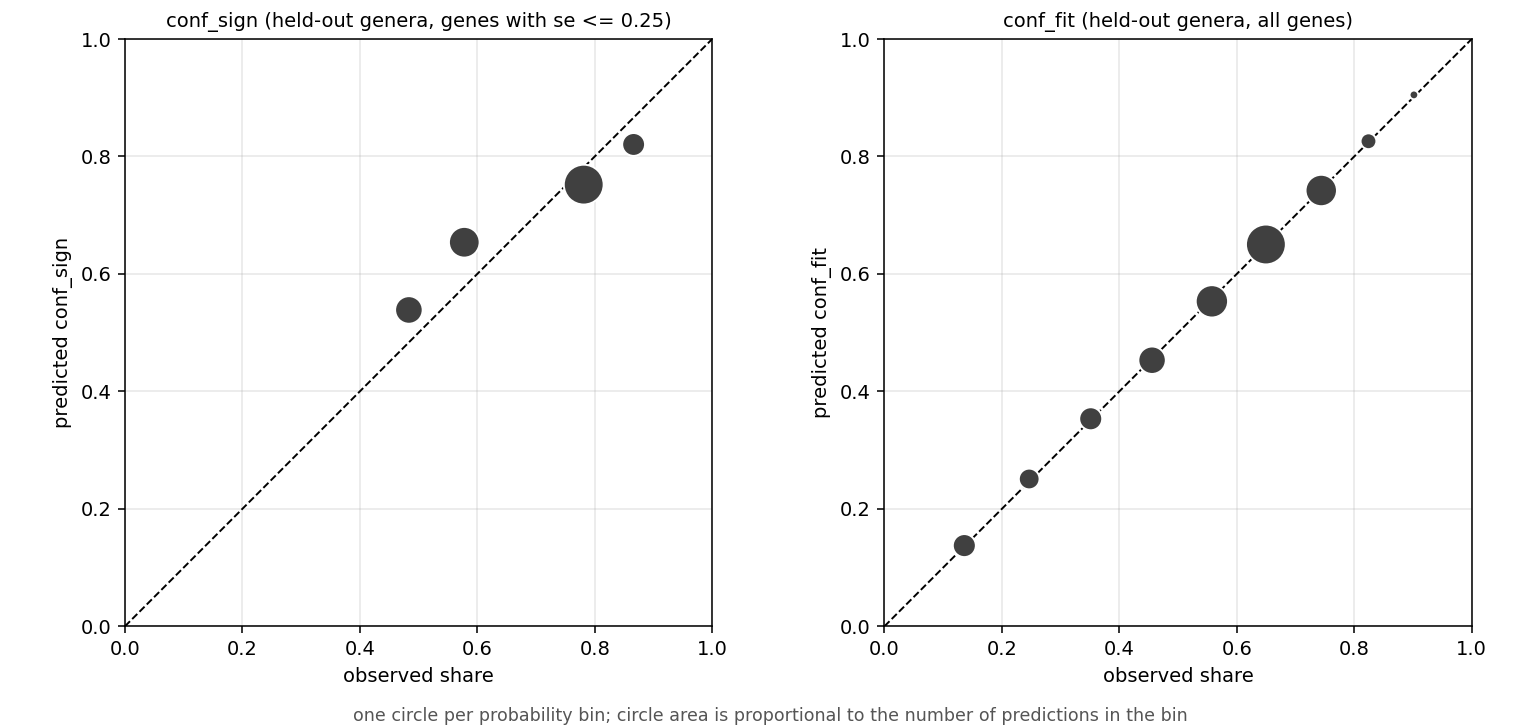

In [5]:
out = []
for genus in R.genus.unique():                                 # genus 하나씩 빼고 학습 -> 뺀 genus 에 적용
    tr, te = R[R.genus != genus], R[R.genus == genus]
    T_k = fit_table(tr, GRID_MU, GRID_LSD)
    out.append(pd.DataFrame({'conf_sign': conf_sign(fit_sign(tr), te.mu.values, te.sd.values),
                             'sign_hit': np.sign(te.y) == np.sign(te.mu), 'low_se': te.se <= SE_MAX,
                             'conf_fit': conf_fit(T_k, GRID_MU, GRID_LSD, te.mu.values, te.sd.values),
                             'fit_hit': np.abs(te.y - te.mu) <= te.sd}))
O = pd.concat(out, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
panels = (('conf_sign', 'sign_hit', O[O.low_se], f'genes with se <= {SE_MAX}'), ('conf_fit', 'fit_hit', O, 'all genes'))
for ax, (c, h, d, who) in zip(axes, panels):
    T = d.groupby(pd.cut(d[c], BINS, right=False), observed=True).agg(n=(h, 'size'), predicted=(c, 'mean'), observed=(h, 'mean'))
    T.index = T.index.astype(str)
    T.round(4).to_csv(f'{OUT_DIR}/check_{c}.csv', index_label='bin')
    print(f'held-out genus check - {c} ({who})'); print(T.round(3).to_string(), '\n')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.scatter(T.observed, T.predicted, s=20 + 400 * T.n / T.n.max(), color='#404040', edgecolor='white', zorder=3)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.grid(alpha=.3)
    ax.set_xlabel('observed share'); ax.set_ylabel(f'predicted {c}'); ax.set_title(f'{c} (held-out genera, {who})', fontsize=10)
fig.text(0.5, 0.01, 'one circle per probability bin; circle area is proportional to the number of predictions in the bin',
         ha='center', fontsize=9, color='#555555')
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(f'{OUT_DIR}/calibration.png', dpi=140); plt.close(fig)

## 5. 최종 보정 함수

전체 예측으로 두 함수를 다시 학습해 `calibration.json` 에 저장한다. 서비스는 이 파일을 `assets/` 에 복사해 예측마다 $\mu$ · $\sigma$ 로 두 확률을 계산한다.

| 키 | 내용 |
|---|---|
| `sign` | `conf_sign` 계수 $\mathbf{w}$ — $(1, L, S, L S)$ 순 |
| `fit` | `conf_fit` 확률표 — `mu` (격자 [101]) · `log_sd` (격자 [29]) · `p` (확률 [101, 29]) |
| `source` · `n_predictions` | 보정 자료 |

효과가 크다고 예측된 유전자일수록 방향은 확실하지만(`conf_sign` 높음) 크기는 맞히기 어렵다(`conf_fit` 낮음).

In [6]:
w_sign  = fit_sign(R)
T_final = fit_table(R, GRID_MU, GRID_LSD)
cal = dict(sign=w_sign.round(6).tolist(),
           fit=dict(mu=GRID_MU.tolist(), log_sd=GRID_LSD.tolist(), p=T_final.round(4).tolist()),
           source='fitpred_ablation/noseq', n_predictions=int(len(R)))
with open(f'{OUT_DIR}/calibration.json', 'w', encoding='utf-8') as f:
    json.dump(cal, f)
print('conf_sign weights (1, L, S, L*S):', cal['sign'])
print('conf_fit table:', T_final.shape, f'| range {T_final.min():.3f} - {T_final.max():.3f}')

# 예시 - 예측 평균 · 표준편차별 두 확률
ex = pd.DataFrame({'mu': [0.1, -0.5, -1.0, -2.0, -4.0, 1.0], 'sd': [0.5, 0.5, 0.5, 0.6, 1.0, 0.4]})
ex['conf_sign'] = conf_sign(w_sign, ex.mu.values, ex.sd.values)
ex['conf_fit']  = conf_fit(T_final, GRID_MU, GRID_LSD, ex.mu.values, ex.sd.values)
print(ex.round(2).to_string(index=False))
print(f'\nsaved {OUT_DIR}/calibration.json | check_conf_sign.csv | check_conf_fit.csv | calibration.png')

conf_sign weights (1, L, S, L*S): [0.318034, 0.5716, -1.243491, 0.326997]
conf_fit table: (101, 29) | range 0.049 - 0.917
  mu  sd  conf_sign  conf_fit
 0.1 0.5       0.63      0.70
-0.5 0.5       0.73      0.31
-1.0 0.5       0.77      0.14
-2.0 0.6       0.78      0.08
-4.0 1.0       0.75      0.10
 1.0 0.4       0.81      0.13

saved ../results/calib_logistic/calibration.json | check_conf_sign.csv | check_conf_fit.csv | calibration.png
